In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
import matplotlib.pyplot as plt

In [4]:
data = pd.read_csv('DATA/sessions_complete.csv')
data.head()

,session_key,session_type,session_name,date_start,date_end,meeting_key,circuit_key,circuit_short_name,country_key,country_code,...,wind_speed,pressure,track_temperature,wind_direction,yellow_flag_count,circuit,lap_length_km,laps,total_track_length_km,track_type
0,9222,Practice,Day 1,2023-02-23T07:00:00+00:00,2023-02-23T16:30:00+00:00,1140,63,Sakhir,36,BRN,...,2.112881,1009.655254,35.970169,205.498305,9.0,Bahrain International Circuit,5.412,57.0,308.484,Race
1,7763,Practice,Day 2,2023-02-24T07:00:00+00:00,2023-02-24T16:30:00+00:00,1140,63,Sakhir,36,BRN,...,2.091695,1009.909661,36.444915,215.825424,2.0,Bahrain International Circuit,5.412,57.0,308.484,Race
2,7764,Practice,Day 3,2023-02-25T07:00:00+00:00,2023-02-25T16:30:00+00:00,1140,63,Sakhir,36,BRN,...,1.154217,1013.120654,36.384682,242.635112,0.0,Bahrain International Circuit,5.412,57.0,308.484,Race
3,7765,Practice,Practice 1,2023-03-03T11:30:00+00:00,2023-03-03T12:30:00+00:00,1141,63,Sakhir,36,BRN,...,2.579762,1017.314286,40.482143,300.095238,2.0,Bahrain International Circuit,5.412,57.0,308.484,Race
4,7766,Practice,Practice 2,2023-03-03T15:00:00+00:00,2023-03-03T16:00:00+00:00,1141,63,Sakhir,36,BRN,...,1.082353,1018.512941,26.972941,244.058824,1.0,Bahrain International Circuit,5.412,57.0,308.484,Race


In [17]:
X = data.drop('yellow_flag_count', axis=1)  # Replace 'target_column' with the actual target column name
y = data['yellow_flag_count']  # Replace 'target_column' with the actual target column name

<Axes: >

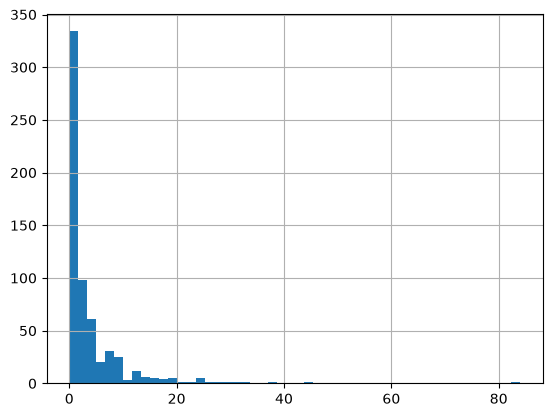

In [10]:
# View yellow flag count distribution

y.hist(bins=50)

In [15]:
# get all the session type names 
session_type_counts = data['session_type'].value_counts()

session_type_counts

session_type
Practice      311
Qualifying    154
Race          154
Name: count, dtype: int64

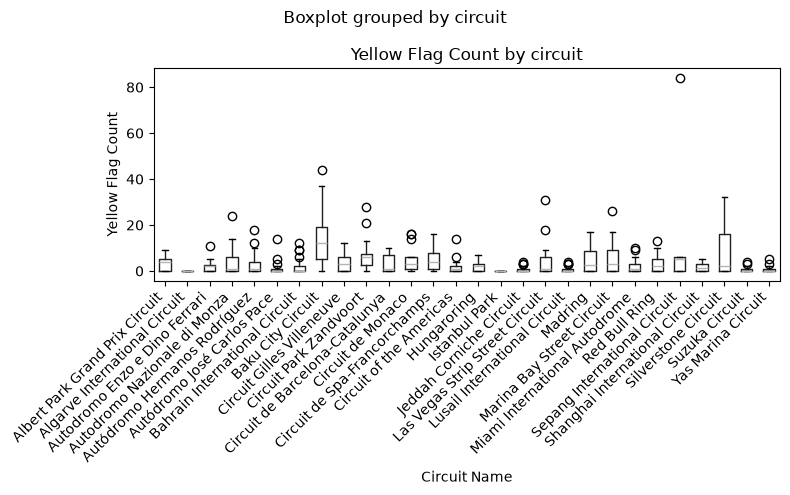

In [10]:
fig, ax = plt.subplots(figsize=(8, 5))
data.boxplot(column='yellow_flag_count', by='circuit', ax=ax, grid=False)
ax.set_title('Yellow Flag Count by circuit')
ax.set_xlabel('Circuit Name')
ax.set_ylabel('Yellow Flag Count')
plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
plt.tight_layout()

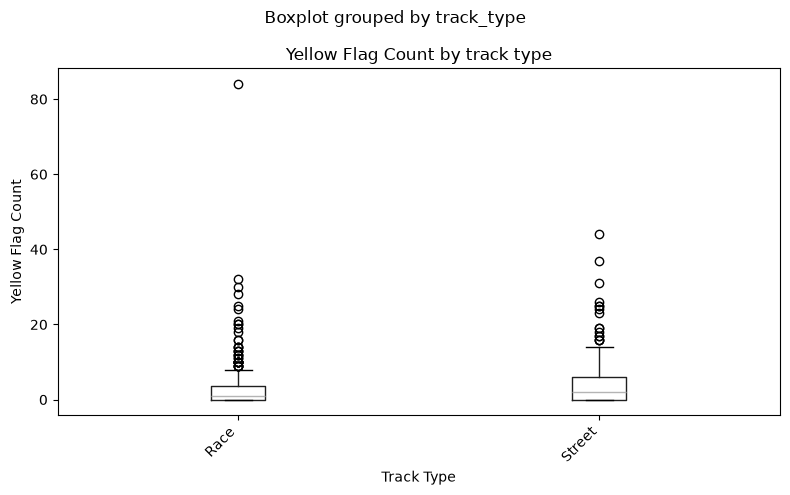

In [15]:
fig, ax = plt.subplots(figsize=(8, 5))
data.boxplot(column='yellow_flag_count', by='track_type', ax=ax, grid=False)
ax.set_title('Yellow Flag Count by track type')
ax.set_xlabel('Track Type')
ax.set_ylabel('Yellow Flag Count')
plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
plt.tight_layout()

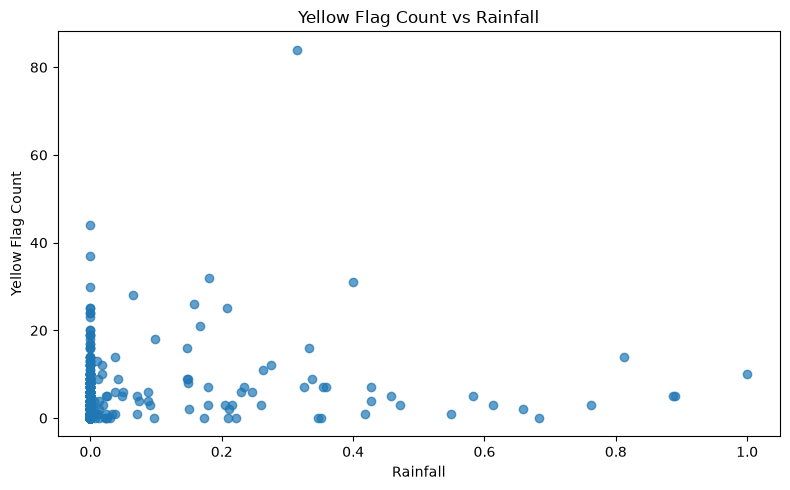

In [12]:
# view flag counts vs rainfall in scatterplot
plot_df = data[['rainfall', 'yellow_flag_count']].dropna()
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(plot_df['rainfall'], plot_df['yellow_flag_count'], alpha=0.7)
ax.set_title('Yellow Flag Count vs Rainfall')
ax.set_xlabel('Rainfall')
ax.set_ylabel('Yellow Flag Count')
plt.tight_layout()

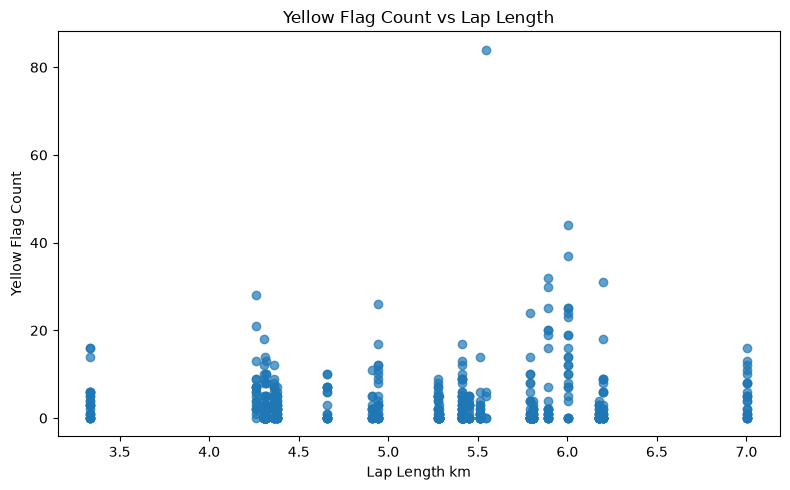

In [14]:
plot_df = data[['lap_length_km', 'yellow_flag_count']].dropna()
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(plot_df['lap_length_km'], plot_df['yellow_flag_count'], alpha=0.7)
ax.set_title('Yellow Flag Count vs Lap Length')
ax.set_xlabel('Lap Length km')
ax.set_ylabel('Yellow Flag Count')
plt.tight_layout()

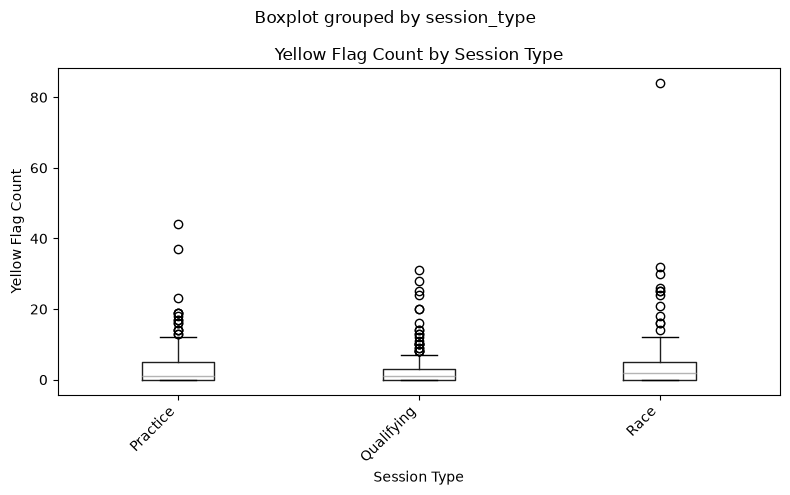

In [9]:
# view yellow flag count boxplot for each session type
fig, ax = plt.subplots(figsize=(8, 5))
data.boxplot(column='yellow_flag_count', by='session_type', ax=ax, grid=False)
ax.set_title('Yellow Flag Count by Session Type')
ax.set_xlabel('Session Type')
ax.set_ylabel('Yellow Flag Count')
plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
plt.tight_layout()